In [20]:
#first lets determine interannual variability to determine downscaling vs climatology prediction

# Purpose: Determine the native spatial skill of the RF precipitation model
# across output resolutions from 1 to 6 km.

# For each resolution the full pipeline runs end-to-end:
#   Section 3 — Resample existing 1km monthly rasters to target resolution
#   Section 4 — Build train + test feature matrices at target resolution
#   Section 5 — Fit and tune global RF (RandomizedSearchCV, 5-fold CV)
#   Section 6 — Predict full monthly rasters at target resolution (optional)
#   Section 7 — Compare R², RMSE, pbias across all resolutions - CHANGE THIS
#
# Source data: 1km monthly rasters already produced by monthly_raster_aggregation.
# No raw daily files are re-read — all resampling is from the 1km outputs.
# 1km uses source rasters directly (no resampling).
#
# OUTPUT FOLDER: ..\Data\Processed\Resolution_Skill_Test\
#   Each resolution writes to its own subfolder (1km/, 2km/, ... 6km/)
#   Final comparison table and plot are written to the root folder.
# =============================================================================

In [21]:
import os
import gc
import glob
import shutil
import numpy as np
import pandas as pd
import xarray as xr
import rioxarray as rxr
import joblib
import matplotlib.pyplot as plt
from rasterio.enums import Resampling
from scipy.spatial import cKDTree
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.model_selection import RandomizedSearchCV
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from tqdm import tqdm


# ── CONFIGURATION ─────────────────────────────────────────────────────────────

START_YEAR, START_MONTH = 2001, 1
END_YEAR,   END_MONTH   = 2005, 12

RESOLUTIONS = [1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5, 5.5, 6]

TEMPLATE_PATHS = {
    1:   r"..\Data\Datasets\TemplateRasters\template_raster_WGS_1km.tif",
    1.5: r"..\Data\Datasets\TemplateRasters\template_raster_WGS_1_5km.tif",
    2:   r"..\Data\Datasets\TemplateRasters\template_raster_WGS_2km.tif",
    2.5: r"..\Data\Datasets\TemplateRasters\template_raster_WGS_2_5km.tif",
    3:   r"..\Data\Datasets\TemplateRasters\template_raster_WGS_3km.tif",
    3.5: r"..\Data\Datasets\TemplateRasters\template_raster_WGS_3_5km.tif",
    4:   r"..\Data\Datasets\TemplateRasters\template_raster_WGS_4km.tif",
    4.5: r"..\Data\Datasets\TemplateRasters\template_raster_WGS_4_5km.tif",
    5:   r"..\Data\Datasets\TemplateRasters\template_raster_WGS_5km.tif",
    5.5: r"..\Data\Datasets\TemplateRasters\template_raster_WGS_5_5km.tif",
    6:   r"..\Data\Datasets\TemplateRasters\template_raster_WGS_6km.tif",
}

# 1km source rasters (Section 3 skips resampling for this resolution)
SOURCE_RASTER_1KM = r"..\Data\Processed\RegressionModel\Monthly_Rasters"

STATIC_PATHS_1KM = {
    "cluster":          r"..\Data\Processed\Spatial_clustering\Precipitation_clusters.tif",
    "elev_mean":        r"..\Data\Datasets\DEM_1km\DEM_1km_elevation_mean.tif",
    "elev_std":         r"..\Data\Datasets\DEM_1km\DEM_1km_elevation_std.tif",
    "elev_max":         r"..\Data\Datasets\DEM_1km\DEM_1km_elevation_max.tif",
    "elev_min":         r"..\Data\Datasets\DEM_1km\DEM_1km_elevation_min.tif",
    "slope_mean":       r"..\Data\Datasets\DEM_1km\DEM_1km_slope_mean.tif",
    "aspect_mean":      r"..\Data\Datasets\DEM_1km\DEM_1km_aspect_mean.tif",
    "elev_smoothed":    r"..\Data\Processed\Fetch\Preprocessing\dem_smoothed.tif",
    "fetch_1000m_dist": r"..\Data\Processed\Fetch\Preprocessing\fetch_dist_1000m.tif",
    "fetch_1000m_dir":  r"..\Data\Processed\Fetch\Preprocessing\fetch_dir_1000m.tif",
    "fetch_500m_dist":  r"..\Data\Processed\Fetch\Preprocessing\fetch_dist_500m.tif",
    "fetch_500m_dir":   r"..\Data\Processed\Fetch\Preprocessing\fetch_dir_500m.tif",
    "local_relief":     r"..\Data\Processed\Fetch\Preprocessing\local_relief.tif",
}

INSITU_CSV     = r"..\Data\Processed\Insitu\insitu_rainfall_1991_2020.csv"
TRAIN_STATIONS = r"..\Data\Processed\Split_stations\train_stations.csv"
TEST_STATIONS  = r"..\Data\Processed\Split_stations\test_stations.csv"

OUT_ROOT = r"..\Data\Processed\Resolution_Skill_Test"

MIN_VALID_DAYS    = 20
RANDOM_STATE      = 64
N_CORES           = 2
N_ITER_SEARCH     = 50
CV_FOLDS          = 5
TARGET_VAR        = "insitu_monthly_total"

PREDICTOR_FEATURES = [
    'y', 'x',
    'era5l_monthly_sum', 'chirps_monthly_sum', 'har_monthly_sum',
    'persiann_monthly_sum', 'mswep_monthly_sum',
    'chirps_wet_day_count', 'chirps_monthly_std',
    'evi_monthly_mean', 'lst_d_monthly_mean', 'lst_d_missing_fraction',
    'lst_n_monthly_mean', 'lst_n_missing_fraction', 'lst_diff_monthly_mean',
    'cluster', 'elev_mean', 'elev_std', 'elev_max', 'elev_min', 'slope_mean',
    'aspect_mean', 'elev_smoothed', 'fetch_1000m_dist', 'fetch_1000m_dir',
    'fetch_500m_dist', 'fetch_500m_dir', 'local_relief', 'month_sin', 'month_cos'
]


RUN_PREDICTION_RASTERS = True

os.makedirs(OUT_ROOT, exist_ok=True)

month_range = pd.period_range(
    start=f"{START_YEAR}-{START_MONTH:02d}",
    end=f"{END_YEAR}-{END_MONTH:02d}",
    freq="M"
)

In [22]:
# SECTION 1 — Helper functions

def mlabel(year: int, month: int) -> str:
    return f"{year}{month:02d}"


def month_cyclical(month: int):
    angle = 2 * np.pi * month / 12
    return np.sin(angle), np.cos(angle)


def kd_threshold(res_km: float) -> float:
    """Scale KD-tree match radius with resolution so coarser grids still capture stations."""
    return 0.006 * res_km


def res_paths(res_km: float) -> dict:
    """Centralised path dictionary for a given resolution — all sections reference this."""
    base = os.path.join(OUT_ROOT, f"{res_km}km")
    return {
        "base":          base,
        "rasters":       os.path.join(base, "Monthly_Rasters"),   # Section 3 writes here
        "static_csv":    os.path.join(base, "static_df.csv"),
        "monthly_train": os.path.join(base, "monthly_train_csv"),
        "monthly_test":  os.path.join(base, "monthly_test_csv"),
        "monthly_pred":  os.path.join(base, "monthly_pred_csv"),
        "train_parquet": os.path.join(base, "train_df.parquet"),
        "test_parquet":  os.path.join(base, "test_df.parquet"),
        "model":         os.path.join(base, "rf_model.pkl"),
        "pred_rasters":  os.path.join(base, "Predicted_Rasters"),  # Section 6 writes here
        "metrics":       os.path.join(base, "metrics.csv"),
    }


def raster_source_dir(res_km: float) -> str:
    """
    Return the directory containing monthly rasters for a given resolution.
    1km  → original source rasters (not resampled).
    >1km → Section 3 output inside the resolution subfolder.
    """
    if res_km == 1:
        return SOURCE_RASTER_1KM
    return res_paths(res_km)["rasters"]


def monthly_raster_paths(year: int, month: int, raster_dir: str) -> dict:
    L = mlabel(year, month)
    R = raster_dir
    return {
        "era5l_monthly_sum":         f"{R}/era5l/era5l_monthly_sum_{L}.tif",
        "chirps_monthly_sum":        f"{R}/chirps/chirps_monthly_sum_{L}.tif",
        "har_monthly_sum":           f"{R}/har/har_monthly_sum_{L}.tif",
        "persiann_monthly_sum":      f"{R}/persiann/persiann_monthly_sum_{L}.tif",
        "mswep_monthly_sum":         f"{R}/mswep/mswep_monthly_sum_{L}.tif",
        "chirps_wet_day_count":      f"{R}/chirps/chirps_wet_day_count_{L}.tif",
        "chirps_monthly_std":        f"{R}/chirps/chirps_monthly_std_{L}.tif",
        "evi_monthly_mean":          f"{R}/modis_evi/evi_monthly_mean_{L}.tif",
        "evi_missing_fraction":      f"{R}/modis_evi/evi_missing_fraction_{L}.tif",
        "lst_d_monthly_mean":        f"{R}/modis_lst/lst_d_monthly_mean_{L}.tif",
        "lst_d_missing_fraction":    f"{R}/modis_lst/lst_d_missing_fraction_{L}.tif",
        "lst_n_monthly_mean":        f"{R}/modis_lst/lst_n_monthly_mean_{L}.tif",
        "lst_n_missing_fraction":    f"{R}/modis_lst/lst_n_missing_fraction_{L}.tif",
        "lst_diff_monthly_mean":     f"{R}/modis_lst/lst_diff_monthly_mean_{L}.tif",
        "lst_diff_missing_fraction": f"{R}/modis_lst/lst_diff_missing_fraction_{L}.tif",
    }


def compute_metrics(y_true, y_pred):
    from scipy.stats import spearmanr
    r2          = r2_score(y_true, y_pred)
    rmse        = np.sqrt(mean_squared_error(y_true, y_pred))
    pbias       = 100 * np.sum(y_pred - y_true) / np.sum(y_true)
    correlation, _ = spearmanr(y_pred, y_true)
    nrmse       = rmse / np.mean(y_true) if np.mean(y_true) != 0 else np.nan
    rsd         = np.std(y_pred) / np.std(y_true) if np.std(y_true) != 0 else np.nan
    return dict(r2=r2, rmse=rmse, pbias=pbias, correlation=correlation,
                nrmse=nrmse, rsd=rsd, n=len(y_true))


def get_rf_param_grid() -> dict:
    return {
        'reg__n_estimators':      [50, 100, 500, 1000, 2000],
        'reg__max_features':      ['sqrt', 'log2'],
        'reg__max_depth':         [None, 10, 20, 30],
        'reg__min_samples_split': [2, 5, 10],
        'reg__min_samples_leaf':  [1, 2, 4],
    }


def load_rasters_to_grid(paths: dict, template: xr.DataArray) -> tuple:
    """Load {name: filepath} rasters, resample to template, return pixel DataFrame."""
    aligned, missing_vars = [], []
    for name, path in paths.items():
        if not os.path.exists(path):
            missing_vars.append(name)
            continue
        da = rxr.open_rasterio(path, masked=True).rio.write_crs("EPSG:4326")
        da = da.rio.reproject_match(template, resampling=Resampling.bilinear)
        if "band" in da.dims and da.sizes["band"] == 1:
            da = da.squeeze("band", drop=True)
        da.name = name
        aligned.append(da.load())
        da.close()
    if not aligned:
        return None, missing_vars
    dynamic_xr = xr.merge(aligned, compat="override")
    dynamic_df = dynamic_xr.to_dataframe().reset_index()
    dynamic_df[["x", "y"]] = dynamic_df[["x", "y"]].round(5)
    for name in missing_vars:
        dynamic_df[name] = np.nan
    del aligned, dynamic_xr
    gc.collect()
    return dynamic_df, missing_vars


def load_static_df(res_km: float, template: xr.DataArray) -> pd.DataFrame:
    """Load or build the static feature dataframe for a given resolution."""
    p = res_paths(res_km)
    if os.path.exists(p["static_csv"]):
        static_df = pd.read_csv(p["static_csv"])
        print(f"    Static df loaded from cache: {len(static_df):,} pixels")
    else:
        print(f"    Building static df (1km rasters → {res_km}km template) ...")
        aligned = []
        for name, path in STATIC_PATHS_1KM.items():
            da = rxr.open_rasterio(path, masked=True).rio.write_crs("EPSG:4326")
            da = da.rio.reproject_match(template, resampling=Resampling.bilinear)
            if "band" in da.dims and da.sizes["band"] == 1:
                da = da.squeeze("band", drop=True)
            da.name = name
            aligned.append(da.load())
            da.close()
        static_xr = xr.merge(aligned, compat="override")
        static_df = static_xr.to_dataframe().reset_index()
        static_df.to_csv(p["static_csv"], index=False)
        del aligned, static_xr
        gc.collect()
        print(f"    Static df built and cached: {len(static_df):,} pixels")
    static_df[["x", "y"]] = static_df[["x", "y"]].round(5)
    return static_df

In [23]:
# SECTION 2 — Load and prepare in-situ monthly data (run once, shared by all resolutions)

insitu_raw = pd.read_csv(INSITU_CSV)
insitu_raw["date"] = pd.to_datetime(insitu_raw[["year", "month", "day"]])
insitu_raw = insitu_raw.rename(columns={"lat": "y", "long": "x",
                                         "rainfall_sum": "insitu_prec"})
insitu_raw = insitu_raw[insitu_raw["insitu_prec"] >= 0]

insitu_monthly = (
    insitu_raw
    .groupby(["index_no", "y", "x", "year", "month"])
    .agg(
        insitu_monthly_total=("insitu_prec", "sum"),
        valid_days          =("insitu_prec", "count"),
    )
    .reset_index()
)

n_before       = len(insitu_monthly)
insitu_monthly = insitu_monthly[insitu_monthly["valid_days"] >= MIN_VALID_DAYS].copy()
print(f"  Completeness filter (≥{MIN_VALID_DAYS} valid days): "
      f"{len(insitu_monthly):,} kept / {n_before:,} total "
      f"({100*(n_before-len(insitu_monthly))/n_before:.1f}% excluded)")

insitu_monthly = insitu_monthly[
    (insitu_monthly["year"] >= START_YEAR) &
    (insitu_monthly["year"] <= END_YEAR)
].copy()
insitu_monthly[["x", "y"]] = insitu_monthly[["x", "y"]].round(5)

train_ids = set(pd.read_csv(TRAIN_STATIONS)["index_no"])
test_ids  = set(pd.read_csv(TEST_STATIONS )["index_no"])

insitu_train = insitu_monthly[insitu_monthly["index_no"].isin(train_ids)].copy()
insitu_test  = insitu_monthly[insitu_monthly["index_no"].isin(test_ids) ].copy()

print(f"  Train: {len(insitu_train):,} station-months  ({insitu_train['index_no'].nunique()} stations)")
print(f"  Test : {len(insitu_test):,} station-months  ({insitu_test['index_no'].nunique()} stations)")

  Completeness filter (≥20 valid days): 23,356 kept / 23,456 total (0.4% excluded)
  Train: 2,886 station-months  (50 stations)
  Test : 1,035 station-months  (18 stations)


In [24]:
# SECTION 3 — Resample monthly rasters to each target resolution

# Writes to: OUT_ROOT/{res_km}km/Monthly_Rasters/  (mirrors source subdirectory tree)
# 1km is skipped — Section 6 reads from SOURCE_RASTER_1KM directly.
 
for res_km in RESOLUTIONS:
    p = res_paths(res_km)

    if res_km == 1:
        print(f"\n  [1km] Using source rasters directly — no resampling needed.")
        continue

    template_path = TEMPLATE_PATHS.get(res_km, "")
    if not template_path or not os.path.exists(template_path):
        print(f"\n  [{res_km}km] Template path not set or not found — skipping.")
        continue

    template = rxr.open_rasterio(template_path, masked=True)
    os.makedirs(p["rasters"], exist_ok=True)

    print(f"\n  [{res_km}km] Resampling → {p['rasters']}")
    n_done = n_skipped = n_failed = 0

    for root, dirs, files in os.walk(SOURCE_RASTER_1KM):
        for fname in [f for f in files if f.endswith(".tif")]:
            src_path  = os.path.join(root, fname)
            rel_path  = os.path.relpath(src_path, SOURCE_RASTER_1KM)
            dest_path = os.path.join(p["rasters"], rel_path)
            os.makedirs(os.path.dirname(dest_path), exist_ok=True)
            if os.path.exists(dest_path):
                n_skipped += 1
                continue
            try:
                da = rxr.open_rasterio(src_path, masked=True).rio.write_crs("EPSG:4326")
                da = da.rio.reproject_match(template, resampling=Resampling.bilinear)
                da = da.rio.write_nodata(-9999.0)
                if '_FillValue' in da.attrs:
                    del da.attrs['_FillValue']
                da.rio.to_raster(dest_path, dtype="float32")
                da.close()
                n_done += 1
            except Exception as e:
                print(f"    WARNING [{fname}]: {e}")
                n_failed += 1

    print(f"    {n_done} resampled | {n_skipped} skipped | {n_failed} failed")

print("\nSection 3 complete.")


  [1km] Using source rasters directly — no resampling needed.

  [1.5km] Resampling → ..\Data\Processed\Resolution_Skill_Test\1.5km\Monthly_Rasters
    900 resampled | 0 skipped | 0 failed

  [2km] Resampling → ..\Data\Processed\Resolution_Skill_Test\2km\Monthly_Rasters
    900 resampled | 0 skipped | 0 failed

  [2.5km] Resampling → ..\Data\Processed\Resolution_Skill_Test\2.5km\Monthly_Rasters
    900 resampled | 0 skipped | 0 failed

  [3km] Resampling → ..\Data\Processed\Resolution_Skill_Test\3km\Monthly_Rasters
    900 resampled | 0 skipped | 0 failed

  [3.5km] Resampling → ..\Data\Processed\Resolution_Skill_Test\3.5km\Monthly_Rasters
    900 resampled | 0 skipped | 0 failed

  [4km] Resampling → ..\Data\Processed\Resolution_Skill_Test\4km\Monthly_Rasters
    900 resampled | 0 skipped | 0 failed

  [4.5km] Resampling → ..\Data\Processed\Resolution_Skill_Test\4.5km\Monthly_Rasters
    900 resampled | 0 skipped | 0 failed

  [5km] Resampling → ..\Data\Processed\Resolution_Skill_Tes

In [25]:
# SECTION 4 — Build feature matrices (train + test) at each resolution
#
# raster_dir resolves via raster_source_dir():
#   1km  → SOURCE_RASTER_1KM
#   >1km → p["rasters"]  (Section 3 output)

for res_km in RESOLUTIONS:
    p         = res_paths(res_km)
    raster_dir = raster_source_dir(res_km)   # FIX: was a hardcoded path in original

    if os.path.exists(p["train_parquet"]) and os.path.exists(p["test_parquet"]):
        print(f"\n  [{res_km}km] Feature matrices already exist — skipping.")
        continue

    template_path = TEMPLATE_PATHS.get(res_km, "")
    if not template_path or not os.path.exists(template_path):
        print(f"\n  [{res_km}km] Template not found — skipping.")
        continue

    template  = rxr.open_rasterio(template_path, masked=True)
    threshold = kd_threshold(res_km)

    os.makedirs(p["base"],          exist_ok=True)
    os.makedirs(p["monthly_train"], exist_ok=True)
    os.makedirs(p["monthly_test"],  exist_ok=True)

    print(f"\n  [{res_km}km] Feature matrix build  (KD threshold: {threshold:.4f}°)")

    static_df = load_static_df(res_km, template)

    for period in tqdm(month_range, desc=f"  [{res_km}km] months"):
        year, month = period.year, period.month
        label       = mlabel(year, month)
        train_out   = os.path.join(p["monthly_train"], f"merged_{label}.csv")
        test_out    = os.path.join(p["monthly_test"],  f"merged_{label}.csv")

        if os.path.exists(train_out) and os.path.exists(test_out):
            continue

        dynamic_df, missing_vars = load_rasters_to_grid(
            monthly_raster_paths(year, month, raster_dir), template
        )
        if dynamic_df is None:
            tqdm.write(f"    [{label}] no rasters — skipping")
            continue
        if missing_vars:
            tqdm.write(f"    [{label}] missing: {missing_vars}")

        monthly_grid = dynamic_df.merge(static_df, on=["x", "y"], how="inner")
        sin_m, cos_m = month_cyclical(month)
        monthly_grid["month_sin"] = sin_m
        monthly_grid["month_cos"] = cos_m
        monthly_grid["year"]  = year
        monthly_grid["month"] = month
        del dynamic_df
        gc.collect()

        tree = cKDTree(monthly_grid[["x", "y"]].values)

        for insitu_split, out_path in [
            (insitu_train, train_out),
            (insitu_test,  test_out),
        ]:
            insitu_m = insitu_split[
                (insitu_split["year"] == year) & (insitu_split["month"] == month)
            ].copy()
            if insitu_m.empty:
                continue
            dist, idx = tree.query(insitu_m[["x", "y"]].values, k=1)
            mask = dist <= threshold
            if mask.any():
                pd.concat([
                    insitu_m.iloc[mask].reset_index(drop=True)[
                        ["index_no", "y", "x", "year", "month",
                         "insitu_monthly_total", "valid_days"]],
                    monthly_grid.iloc[idx[mask]].reset_index(drop=True)
                               .drop(columns=["x", "y", "year", "month"])
                ], axis=1).to_csv(out_path, index=False)

        del monthly_grid, insitu_m
        gc.collect()

    for split, csv_dir, out_parquet in [
        ("train", p["monthly_train"], p["train_parquet"]),
        ("test",  p["monthly_test"],  p["test_parquet"]),
    ]:
        files = sorted(glob.glob(os.path.join(csv_dir, "merged_*.csv")))
        if not files:
            print(f"    WARNING: no {split} CSV files for [{res_km}km]")
            continue
        df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
        df.to_parquet(out_parquet, index=False)
        print(f"    [{split}] {len(df):,} rows × {len(df.columns)} cols → {out_parquet}")
        del df

    for d in [p["monthly_train"], p["monthly_test"]]:
        if os.path.exists(d):
            shutil.rmtree(d)
            print(f"    Cleaned: {d}")


  [1km] Feature matrix build  (KD threshold: 0.0060°)
    Building static df (1km rasters → 1km template) ...
    Static df built and cached: 484,619 pixels


  [1km] months: 100%|██████████| 60/60 [01:20<00:00,  1.34s/it]


    [train] 2,886 rows × 39 cols → ..\Data\Processed\Resolution_Skill_Test\1km\train_df.parquet
    [test] 1,035 rows × 39 cols → ..\Data\Processed\Resolution_Skill_Test\1km\test_df.parquet
    Cleaned: ..\Data\Processed\Resolution_Skill_Test\1km\monthly_train_csv
    Cleaned: ..\Data\Processed\Resolution_Skill_Test\1km\monthly_test_csv

  [1.5km] Feature matrix build  (KD threshold: 0.0090°)
    Building static df (1km rasters → 1.5km template) ...
    Static df built and cached: 214,840 pixels


  [1.5km] months: 100%|██████████| 60/60 [01:04<00:00,  1.07s/it]


    [train] 2,886 rows × 39 cols → ..\Data\Processed\Resolution_Skill_Test\1.5km\train_df.parquet
    [test] 1,035 rows × 39 cols → ..\Data\Processed\Resolution_Skill_Test\1.5km\test_df.parquet
    Cleaned: ..\Data\Processed\Resolution_Skill_Test\1.5km\monthly_train_csv
    Cleaned: ..\Data\Processed\Resolution_Skill_Test\1.5km\monthly_test_csv

  [2km] Feature matrix build  (KD threshold: 0.0120°)
    Building static df (1km rasters → 2km template) ...
    Static df built and cached: 120,786 pixels


...

    [train] 2,826 rows × 39 cols → ..\Data\Processed\Resolution_Skill_Test\5km\train_df.parquet
    [test] 1,035 rows × 39 cols → ..\Data\Processed\Resolution_Skill_Test\5km\test_df.parquet
    Cleaned: ..\Data\Processed\Resolution_Skill_Test\5km\monthly_train_csv
    Cleaned: ..\Data\Processed\Resolution_Skill_Test\5km\monthly_test_csv

  [5.5km] Feature matrix build  (KD threshold: 0.0330°)
    Building static df (1km rasters → 5.5km template) ...
    Static df built and cached: 15,842 pixels


  [5.5km] months: 100%|██████████| 60/60 [00:42<00:00,  1.41it/s]


    [train] 2,886 rows × 39 cols → ..\Data\Processed\Resolution_Skill_Test\5.5km\train_df.parquet
    [test] 1,035 rows × 39 cols → ..\Data\Processed\Resolution_Skill_Test\5.5km\test_df.parquet
    Cleaned: ..\Data\Processed\Resolution_Skill_Test\5.5km\monthly_train_csv
    Cleaned: ..\Data\Processed\Resolution_Skill_Test\5.5km\monthly_test_csv

  [6km] Feature matrix build  (KD threshold: 0.0360°)
    Building static df (1km rasters → 6km template) ...
    Static df built and cached: 13,366 pixels


  [6km] months: 100%|██████████| 60/60 [00:42<00:00,  1.42it/s]


    [train] 2,886 rows × 39 cols → ..\Data\Processed\Resolution_Skill_Test\6km\train_df.parquet
    [test] 1,035 rows × 39 cols → ..\Data\Processed\Resolution_Skill_Test\6km\test_df.parquet
    Cleaned: ..\Data\Processed\Resolution_Skill_Test\6km\monthly_train_csv
    Cleaned: ..\Data\Processed\Resolution_Skill_Test\6km\monthly_test_csv


In [26]:
# SECTION 5 — Fit one RF per resolution

for res_km in RESOLUTIONS:
    p = res_paths(res_km)

    if os.path.exists(p["metrics"]):
        print(f"\n  [{res_km}km] Metrics already exist — skipping model fit.")
        continue

    if not (os.path.exists(p["train_parquet"]) and os.path.exists(p["test_parquet"])):
        print(f"\n  [{res_km}km] Feature matrices not found — run Section 4 first.")
        continue

    print(f"\n  [{res_km}km] Fitting RF ...")

    train_df = pd.read_parquet(p["train_parquet"])
    test_df  = pd.read_parquet(p["test_parquet"])

    for col in PREDICTOR_FEATURES:
        if col not in train_df.columns: train_df[col] = np.nan
        if col not in test_df.columns:  test_df[col]  = np.nan

    X_train = train_df[PREDICTOR_FEATURES].values
    y_train = train_df[TARGET_VAR].values
    X_test  = test_df[PREDICTOR_FEATURES].values
    y_test  = test_df[TARGET_VAR].values

    print(f"    Train: {len(X_train):,} rows  |  Test: {len(X_test):,} rows")

    model = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('reg',     RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=N_CORES)),
    ])
    search = RandomizedSearchCV(
        estimator=model,
        param_distributions=get_rf_param_grid(),
        n_iter=N_ITER_SEARCH,
        cv=CV_FOLDS,
        scoring='neg_root_mean_squared_error',
        random_state=RANDOM_STATE,
        n_jobs=N_CORES,
        verbose=0,
    )
    search.fit(X_train, y_train)
    best_model = search.best_estimator_

    train_m = compute_metrics(y_train, best_model.predict(X_train))
    test_m  = compute_metrics(y_test,  best_model.predict(X_test))

    print(f"    CV RMSE     : {-search.best_score_:.4f}")
    print(f"    Train R²    : {train_m['r2']:.4f}   RMSE: {train_m['rmse']:.4f}")
    print(f"    Test  R²    : {test_m['r2']:.4f}   RMSE: {test_m['rmse']:.4f}")
    print(f"    Test  pbias : {test_m['pbias']:.2f}%")
    print(f"    Test  corr  : {test_m['correlation']:.4f}")
    print(f"    Test  NRMSE : {test_m['nrmse']:.4f}")
    print(f"    Test  RSD   : {test_m['rsd']:.4f}")

    os.makedirs(p["base"], exist_ok=True)
    joblib.dump(best_model, p["model"])
    print(f"    Model saved : {p['model']}")

    pd.DataFrame([{
        "resolution_km":     res_km,
        "train_r2":          train_m["r2"],
        "train_rmse":        train_m["rmse"],
        "train_pbias":       train_m["pbias"],
        "train_correlation": train_m["correlation"],
        "train_nrmse":       train_m["nrmse"],
        "train_rsd":         train_m["rsd"],
        "train_n":           train_m["n"],
        "test_r2":           test_m["r2"],
        "test_rmse":         test_m["rmse"],
        "test_pbias":        test_m["pbias"],
        "test_correlation":  test_m["correlation"],
        "test_nrmse":        test_m["nrmse"],
        "test_rsd":          test_m["rsd"],
        "test_n":            test_m["n"],
        "cv_rmse":           round(-search.best_score_, 4),
        "best_params":       str(search.best_params_),
    }]).to_csv(p["metrics"], index=False)
    print(f"    Metrics saved: {p['metrics']}")

    del train_df, test_df, best_model, search
    gc.collect()


  [1km] Fitting RF ...
    Train: 2,886 rows  |  Test: 1,035 rows
    CV RMSE     : 77.2436
    Train R²    : 0.9578   RMSE: 37.8769
    Test  R²    : 0.7824   RMSE: 90.5046
    Test  pbias : -9.59%
    Test  corr  : 0.9147
    Test  NRMSE : 0.6309
    Test  RSD   : 0.7808
    Model saved : ..\Data\Processed\Resolution_Skill_Test\1km\rf_model.pkl
    Metrics saved: ..\Data\Processed\Resolution_Skill_Test\1km\metrics.csv

  [1.5km] Fitting RF ...
    Train: 2,886 rows  |  Test: 1,035 rows
    CV RMSE     : 76.6697
    Train R²    : 0.9538   RMSE: 39.6286
    Test  R²    : 0.7855   RMSE: 89.8647
    Test  pbias : -10.14%
    Test  corr  : 0.9143
    Test  NRMSE : 0.6265
    Test  RSD   : 0.7703
    Model saved : ..\Data\Processed\Resolution_Skill_Test\1.5km\rf_model.pkl
    Metrics saved: ..\Data\Processed\Resolution_Skill_Test\1.5km\metrics.csv

  [2km] Fitting RF ...
    Train: 2,826 rows  |  Test: 1,035 rows
    CV RMSE     : 77.0570
    Train R²    : 0.9586   RMSE: 37.3761
    Test 

In [27]:
# SECTION 6 — Predict full monthly rasters using each resolution's own RF model
#
# Each resolution's model (fitted in Section 5) predicts over the full domain
# at that resolution. Outputs: OUT_ROOT/{res_km}km/Predicted_Rasters/pred_monthly_YYYYMM.tif
#
# raster_source_dir() ensures each resolution reads its own resampled inputs,
# exactly mirroring the feature matrix construction in Section 4.

if RUN_PREDICTION_RASTERS:
    for res_km in RESOLUTIONS:
        p          = res_paths(res_km)
        model_path = p["model"]

        if not os.path.exists(model_path):
            print(f"\n  [{res_km}km] No model found — run Section 5 first.")
            continue

        template_path = TEMPLATE_PATHS.get(res_km, "")
        if not template_path or not os.path.exists(template_path):
            print(f"\n  [{res_km}km] Template not found — skipping.")
            continue

        if not os.path.exists(p["static_csv"]):
            print(f"\n  [{res_km}km] static_df.csv not found — run Section 4 first.")
            continue

        os.makedirs(p["pred_rasters"], exist_ok=True)

        template   = rxr.open_rasterio(template_path, masked=True)
        best_model = joblib.load(model_path)
        static_df  = load_static_df(res_km, template)
        raster_dir = raster_source_dir(res_km)

        print(f"\n  [{res_km}km] Predicting rasters with {res_km}km RF model ...")
        print(f"    Source rasters : {raster_dir}")
        print(f"    Output         : {p['pred_rasters']}")

        n_done = n_skipped = n_failed = 0

        for period in tqdm(month_range, desc=f"  [{res_km}km] predicting"):
            year, month = period.year, period.month
            label       = mlabel(year, month)
            out_path    = os.path.join(p["pred_rasters"], f"pred_monthly_{label}.tif")

            if os.path.exists(out_path):
                n_skipped += 1
                continue

            try:
                # Build full-grid feature matrix (same logic as Section 4, no station matching)
                dynamic_df, missing_vars = load_rasters_to_grid(
                    monthly_raster_paths(year, month, raster_dir), template
                )
                if dynamic_df is None:
                    tqdm.write(f"    [{label}] no dynamic rasters — skipping")
                    n_failed += 1
                    continue

                monthly_grid = dynamic_df.merge(static_df, on=["x", "y"], how="inner")
                sin_m, cos_m = month_cyclical(month)
                monthly_grid["month_sin"] = sin_m
                monthly_grid["month_cos"] = cos_m

                # Ensure all predictor columns are present (fill gaps with NaN for imputer)
                for col in PREDICTOR_FEATURES:
                    if col not in monthly_grid.columns:
                        monthly_grid[col] = np.nan

                # Predict
                X_grid = monthly_grid[PREDICTOR_FEATURES].values
                monthly_grid["prediction"] = best_model.predict(X_grid)

                # Reconstruct 2-D raster from pixel DataFrame and write to GeoTIFF
                pred_da = (
                    monthly_grid
                    .set_index(["y", "x"])["prediction"]
                    .to_xarray()
                    .rio.write_crs("EPSG:4326")
                    .rio.write_nodata(-9999.0)
                )
                pred_da.rio.to_raster(out_path, dtype="float32")

                del dynamic_df, monthly_grid, pred_da
                gc.collect()
                n_done += 1

            except Exception as e:
                tqdm.write(f"    [{label}] ERROR: {e}")
                n_failed += 1

        print(f"    {n_done} predicted | {n_skipped} skipped (exists) | {n_failed} failed")

        del best_model, template, static_df
        gc.collect()

    print("\nSection 6 complete.")

    Static df loaded from cache: 484,619 pixels

  [1km] Predicting rasters with 1km RF model ...
    Source rasters : ..\Data\Processed\RegressionModel\Monthly_Rasters
    Output         : ..\Data\Processed\Resolution_Skill_Test\1km\Predicted_Rasters


  [1km] predicting: 100%|██████████| 60/60 [05:44<00:00,  5.74s/it]


    60 predicted | 0 skipped (exists) | 0 failed
    Static df loaded from cache: 214,840 pixels

  [1.5km] Predicting rasters with 1.5km RF model ...
    Source rasters : ..\Data\Processed\Resolution_Skill_Test\1.5km\Monthly_Rasters
    Output         : ..\Data\Processed\Resolution_Skill_Test\1.5km\Predicted_Rasters


  [1.5km] predicting: 100%|██████████| 60/60 [01:31<00:00,  1.52s/it]


    60 predicted | 0 skipped (exists) | 0 failed
    Static df loaded from cache: 120,786 pixels

  [2km] Predicting rasters with 2km RF model ...
    Source rasters : ..\Data\Processed\Resolution_Skill_Test\2km\Monthly_Rasters
    Output         : ..\Data\Processed\Resolution_Skill_Test\2km\Predicted_Rasters


...

    60 predicted | 0 skipped (exists) | 0 failed
    Static df loaded from cache: 15,842 pixels

  [5.5km] Predicting rasters with 5.5km RF model ...
    Source rasters : ..\Data\Processed\Resolution_Skill_Test\5.5km\Monthly_Rasters
    Output         : ..\Data\Processed\Resolution_Skill_Test\5.5km\Predicted_Rasters


  [5.5km] predicting: 100%|██████████| 60/60 [00:45<00:00,  1.33it/s]


    60 predicted | 0 skipped (exists) | 0 failed
    Static df loaded from cache: 13,366 pixels

  [6km] Predicting rasters with 6km RF model ...
    Source rasters : ..\Data\Processed\Resolution_Skill_Test\6km\Monthly_Rasters
    Output         : ..\Data\Processed\Resolution_Skill_Test\6km\Predicted_Rasters


  [6km] predicting: 100%|██████████| 60/60 [00:54<00:00,  1.10it/s]

    60 predicted | 0 skipped (exists) | 0 failed

Section 6 complete.


In [28]:
# SECTION 7 — Aggregate metrics and compute CPI across all resolutions
#
# FIXES vs original:
#   - Loop variable was res_km (last value from Section 5 loop) instead of RES.
#   - CPI and inversion were inside the per-column normalisation loop,
#     so they were recomputed and re-inverted on every iteration.

def normalize_column(col: pd.Series) -> pd.Series:
    rng = col.max() - col.min()
    return (col - col.min()) / rng if rng != 0 else col * 0

df_metric = pd.DataFrame()

for RES in RESOLUTIONS:                                      # FIX: was res_km
    metric_path = os.path.join(OUT_ROOT, f"{RES}km", "metrics.csv")
    if not os.path.exists(metric_path):
        print(f"  [{RES}km] metrics.csv not found — skipping.")
        continue
    df_metric = pd.concat(
        [df_metric, pd.read_csv(metric_path)], ignore_index=True
    )

df_metric = df_metric[[
    'resolution_km', 'test_correlation', 'test_nrmse', 'test_pbias', 'test_rsd'
]].copy()
df_metric['abs_pbias'] = df_metric['test_pbias'].abs()
df_metric['diff_rsd']  = (df_metric['test_rsd'] - 1).abs()

metrics_to_norm = ['test_correlation', 'test_nrmse', 'abs_pbias', 'diff_rsd']

df_norm = df_metric.copy()

# Normalise each metric to [0, 1]
for col in metrics_to_norm:                                  # FIX: CPI outside loop
    df_norm[col] = normalize_column(df_norm[col])

# Invert correlation so 0 = best for every component
df_norm['test_correlation'] = 1 - df_norm['test_correlation']

# CPI: sum of normalised components (lower = better)
df_norm['cpi']      = df_norm[metrics_to_norm].sum(axis=1)
df_norm['cpi_rank'] = df_norm['cpi'].rank(ascending=True)

df_metric_final = (
    df_norm[['resolution_km', 'cpi', 'cpi_rank']]
    .merge(
        df_metric[['resolution_km', 'test_correlation',
                   'test_nrmse', 'test_pbias', 'test_rsd']],
        on='resolution_km', how='inner'
    )
    .sort_values('resolution_km')
    .reset_index(drop=True)
)

print(df_metric_final.to_string(index=False))



 resolution_km      cpi  cpi_rank  test_correlation  test_nrmse  test_pbias  test_rsd
           1.0 1.569074       6.0          0.914731    0.630930   -9.586561  0.780799
           1.5 2.100117       8.0          0.914341    0.626469  -10.138215  0.770267
           2.0 1.269239       4.0          0.915024    0.625821   -9.255223  0.779798
           2.5 1.026409       3.0          0.913960    0.638544   -7.665170  0.786908
           3.0 0.742466       2.0          0.915299    0.634538   -8.195509  0.790192
           3.5 0.098534       1.0          0.915973    0.627964   -7.242055  0.789760
           4.0 2.505635       9.0          0.914290    0.642985   -9.620837  0.771144
           4.5 3.313794      11.0          0.908354    0.652657   -8.711502  0.771548
           5.0 2.059148       7.0          0.914188    0.642129   -9.296510  0.778449
           5.5 1.556409       5.0          0.914414    0.633263   -9.176398  0.780792
           6.0 2.783323      10.0          0.914728   

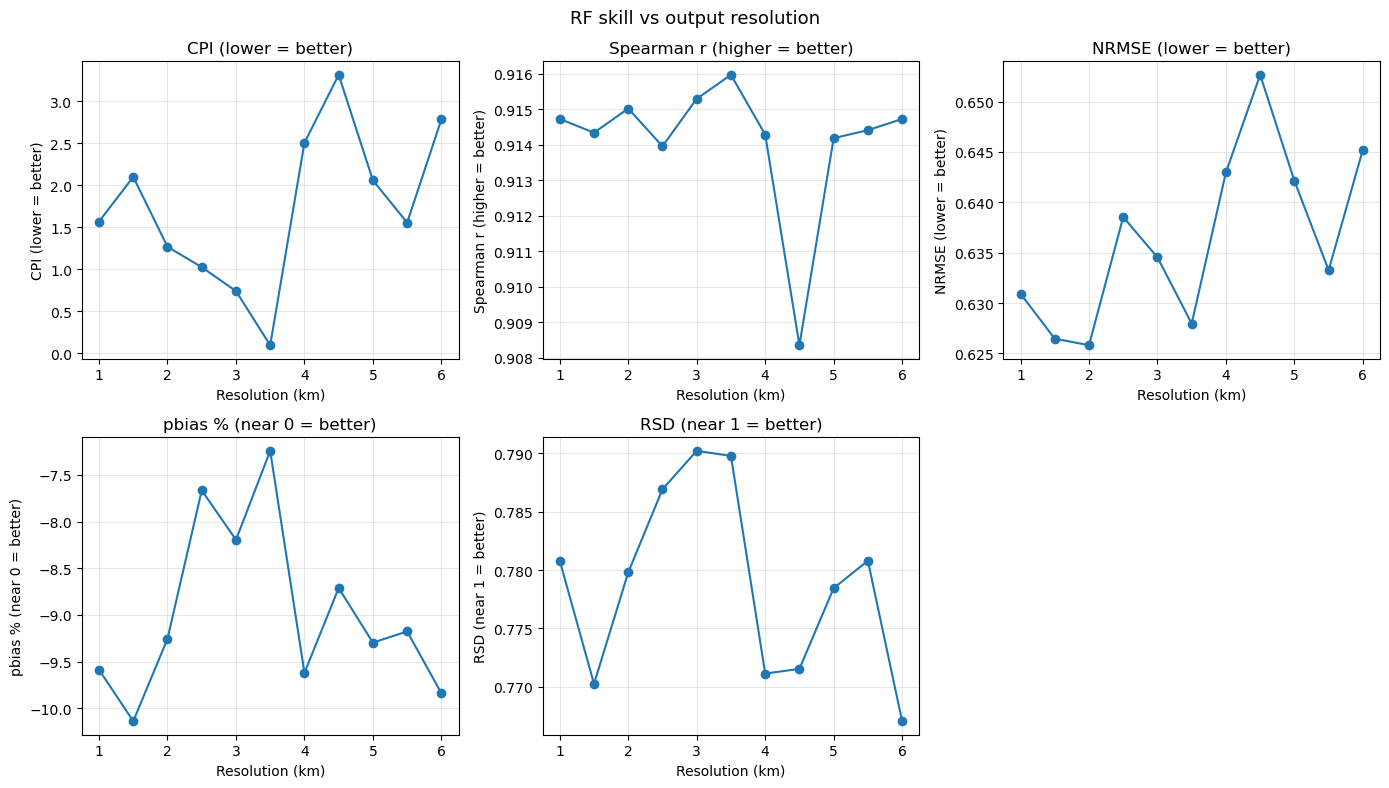

Plot saved to ..\Data\Processed\Resolution_Skill_Test


In [29]:
# SECTION 8 — Plot CPI and individual metrics vs resolution

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
fig.suptitle("RF skill vs output resolution", fontsize=13)

plot_specs = [
    ('cpi',              'CPI (lower = better)',      axes[0, 0]),
    ('test_correlation', 'Spearman r (higher = better)', axes[0, 1]),
    ('test_nrmse',       'NRMSE (lower = better)',    axes[0, 2]),
    ('test_pbias',       'pbias % (near 0 = better)', axes[1, 0]),
    ('test_rsd',         'RSD (near 1 = better)',     axes[1, 1]),
]

for col, ylabel, ax in plot_specs:
    src = df_metric_final if col == 'cpi' else df_metric_final
    ax.plot(df_metric_final['resolution_km'], df_metric_final[col],
            marker='o', linewidth=1.5)
    ax.set_xlabel("Resolution (km)")
    ax.set_ylabel(ylabel)
    ax.set_title(ylabel)
    ax.grid(True, alpha=0.3)

axes[1, 2].axis('off')
plt.tight_layout()
plt.savefig(os.path.join(OUT_ROOT, "resolution_skill_comparison.png"),
            dpi=150, bbox_inches='tight')
plt.show()
print(f"Plot saved to {OUT_ROOT}")